In [ ]:
import pandas as pd

#read csv
df = pd.read_csv("literature_set_bonafide.csv", sep="\t", header=0)
print(len(df))
#print(df.head(1))

#get the second-to-last column
seqs = df[["Sequence_from_PMID","smallBARNA_ID"]]
print(seqs)
print(len(df["Sequence_from_PMID"].unique()))
print(len(df["smallBARNA_ID"].unique()))
##write FASTA
with open("SmallBARNA.fa", "w") as f:
    for _, row in seqs.iterrows():
        seq = str(row["Sequence_from_PMID"]).strip()
        smallbarna_id = row["smallBARNA_ID"]

        if pd.notna(row["Sequence_from_PMID"]) and seq:
            f.write(f">{smallbarna_id}\n{seq}\n")

746
                                    Sequence_from_PMID  smallBARNA_ID
0    TAAGGACGTTTTTTGAAAAGAAAAATGGAGTTGGTCGATAAGCCGG...  sRNA-Aacti-52
1    CTGCTCTACCGACTGAGCTAACGACCCTTTAGAAGGCGTTGCAAGT...  sRNA-Apleu-10
2    ATAAATTCGCAAAAAGTGCTTGCATTGGTTTTGGAAATCTCTATAA...   sRNA-Apleu-3
3    TATGACCTTTGGGTTATGAGCCCAACGAGCTACCAGCTGCTCCACC...   sRNA-Linte-7
4    ACGCCCTCTTGTGGGGCGTTGAGGCCGTTTTCAGGGCATTTTCGCC...   sRNA-Paeru-1
..                                                 ...            ...
741  TGAACTCACAGTCAATCGCCATAAACTGACGGAGTAATAAACAAAG...  sRNA-Aacti-70
742  GATGATATACCAAAATGGTTTATTTTATTTTGATGTAGAAATTGAA...  sRNA-Aacti-71
743  CTGTCTTTGGGTTCCTTAAGCATAATGACAAGATTTATACCGTCGC...   sRNA-Aacti-8
744  GGATGAAACTTAATGCAAGTATGGTTGTGTGTTTTATCAAAAAAAC...   sRNA-Aacti-9
745  TTAATGCTCAACTCTGTGTTAGTGATAGGGGTTGTAGCGATGTGAA...  sRNA-Aacti-51

[746 rows x 2 columns]
738
746


In [4]:
from Bio import SeqIO

lengths = [len(record.seq) for record in SeqIO.parse("SmallBARNA.fa", "fasta")]

print("Minimum length:", min(lengths))
print("Maximum length:", max(lengths))

Minimum length: 25
Maximum length: 1236


In [4]:
lengths = []
seq = ""

with open("SmallBARNA.fa") as f:
    for line in f:
        line = line.strip()
        if line.startswith(">"):
            if seq:
                lengths.append(len(seq))
            seq = ""
        else:
            seq += line

if seq:
    lengths.append(len(seq))

print("Minimum length:", min(lengths))
print("Maximum length:", max(lengths))

Minimum length: 25
Maximum length: 1236


In [ ]:
import pandas as pd

#make bins
length_bins = {(start, start + 10): 0 for start in range(10, 1000, 10)}

all_lengths = []

with open("SmallBARNA.fa", "r") as f:
    for i, seq in enumerate(seqs, start=1):
        if pd.notna(seq):
            seq = str(seq).strip()
            seq_len = len(seq)

            #save length
            all_lengths.append(seq_len)

            #count length into bin
            for start, end in length_bins:
                if start <= seq_len <= end:
                    length_bins[(start, end)] += 1
                    break

            #write fasta if needed
            #f.write(f">srna_{i}\n{seq}\n")

#print bins
for (start, end), count in length_bins.items():
    print(f"{start}-{end}nt : {count}")

#print min and max length
print("Minimum length:", min(all_lengths))
print("Maximum length:", max(all_lengths))

NameError: name 'seqs' is not defined

In [ ]:
import pandas as pd

#make bins
length_bins = {(start, start + 10): 0 for start in range(10, 1000, 10)}

with open("SmallBARNA.fa", "w") as f:
    for i, seq in enumerate(seqs, start=1):
        if pd.notna(seq):
            seq = str(seq).strip()
            seq_len = len(seq)

            #count length into bin
            for start, end in length_bins:
                if start <= seq_len <= end:
                    length_bins[(start, end)] += 1
                    break

            ##write fasta
            #f.write(f">srna_{i}\n{seq}\n")

#print result
for (start, end), count in length_bins.items():
    print(f"{start}-{end}nt : {count}")

10-20nt : 0
20-30nt : 5
30-40nt : 10
40-50nt : 25
50-60nt : 27
60-70nt : 33
70-80nt : 50
80-90nt : 57
90-100nt : 57
100-110nt : 47
110-120nt : 41
120-130nt : 31
130-140nt : 31
140-150nt : 39
150-160nt : 27
160-170nt : 20
170-180nt : 30
180-190nt : 15
190-200nt : 26
200-210nt : 17
210-220nt : 16
220-230nt : 12
230-240nt : 7
240-250nt : 13
250-260nt : 11
260-270nt : 7
270-280nt : 7
280-290nt : 3
290-300nt : 6
300-310nt : 11
310-320nt : 4
320-330nt : 4
330-340nt : 4
340-350nt : 4
350-360nt : 5
360-370nt : 10
370-380nt : 2
380-390nt : 3
390-400nt : 2
400-410nt : 2
410-420nt : 3
420-430nt : 2
430-440nt : 3
440-450nt : 1
450-460nt : 1
460-470nt : 0
470-480nt : 3
480-490nt : 3
490-500nt : 1
500-510nt : 0
510-520nt : 1
520-530nt : 0
530-540nt : 0
540-550nt : 0
550-560nt : 0
560-570nt : 0
570-580nt : 0
580-590nt : 0
590-600nt : 0
600-610nt : 0
610-620nt : 1
620-630nt : 0
630-640nt : 1
640-650nt : 0
650-660nt : 1
660-670nt : 0
670-680nt : 0
680-690nt : 0
690-700nt : 1
700-710nt : 0
710-720nt : 0

0      TAAGGACGTTTTTTGAAAAGAAAAATGGAGTTGGTCGATAAGCCGG...
1      CTGCTCTACCGACTGAGCTAACGACCCTTTAGAAGGCGTTGCAAGT...
2      ATAAATTCGCAAAAAGTGCTTGCATTGGTTTTGGAAATCTCTATAA...
3      TATGACCTTTGGGTTATGAGCCCAACGAGCTACCAGCTGCTCCACC...
4      ACGCCCTCTTGTGGGGCGTTGAGGCCGTTTTCAGGGCATTTTCGCC...
                             ...                        
741    TGAACTCACAGTCAATCGCCATAAACTGACGGAGTAATAAACAAAG...
742    GATGATATACCAAAATGGTTTATTTTATTTTGATGTAGAAATTGAA...
743    CTGTCTTTGGGTTCCTTAAGCATAATGACAAGATTTATACCGTCGC...
744    GGATGAAACTTAATGCAAGTATGGTTGTGTGTTTTATCAAAAAAAC...
745    TTAATGCTCAACTCTGTGTTAGTGATAGGGGTTGTAGCGATGTGAA...
Name: Sequence_from_PMID, Length: 746, dtype: object


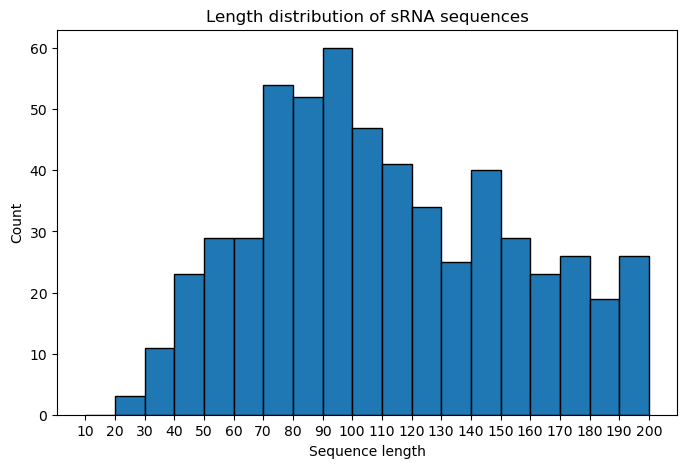

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

#read csv
df = pd.read_csv("literature_set_bonafide.csv", sep="\t", header=0)
#print(df.head(1))

##get the second-to-last column
seqs = df["Sequence_from_PMID"]
print(seqs)

#clean lengths
lengths = [len(str(seq).strip()) for seq in seqs if pd.notna(seq)]

#define bins: 10-20, 20-30, ..., 190-200
bin_edges = list(range(10, 210, 10))

plt.figure(figsize=(8, 5))
plt.hist(lengths, bins=bin_edges, edgecolor='black')
plt.xlabel("Sequence length")
plt.ylabel("Count")
plt.title("Length distribution of sRNA sequences")
plt.xticks(bin_edges)
plt.show()

In [ ]:
import pandas as pd

#read csv
df = pd.read_csv("literature_set_bonafide.csv", sep="\t", header=0)
print(len(df))
print(df.head(1))

746
  Validated_in_Pubmed                                Associated_sRNA_IDs  \
0            29211829  URS0000E6094C_1907939, URS0000E5FEBF_638300, U...   

              Validated_in_Species Validated_in_Genomes  Validated_in_Taxid  \
0  A. actinomycetemcomitans HK1651           CP007502.1            700685.0   

  Evidence_RNAseq Evidence_Northern_Blot Evidence_RT_pcr Evidence_qPCR  \
0             Yes                    Yes             Yes           Yes   

  Evidence_Other Evidence_Functional_analysis Evidence_Diff_Exp  \
0             No                           No               Yes   

  Validated_Under_Conditions RNA_seq_accession Literature_Synonyms  \
0              Growth phases         DRR088289         AaHKsRNA090   

   smallBARNA_ID Validated_in_Tissue  \
0  sRNA-Aacti-52      Medium culture   

                                  Sequence_from_PMID  Direction_from_PMID  
0  TAAGGACGTTTTTTGAAAAGAAAAATGGAGTTGGTCGATAAGCCGG...                 -1.0  


In [2]:
filtered = df[
    df["Sequence_from_PMID"].notna() &
    (df["Sequence_from_PMID"].astype(str).str.strip().str.len() <= 40)
][["Sequence_from_PMID", "Validated_in_Pubmed"]]

print(filtered)

                           Sequence_from_PMID Validated_in_Pubmed
55        TTCAGGGACGTCATTACGGGCAGGGATGCCCACCC            36354005
282          CTTATTCAAGTTTACATATTATACTCAATGAA            22807675
309              ATTGAACCTCGAGAACCGTTGTCTTATA            20460466
311                 CATAGCGTGGCAACAGCGCGCCGTC            20460466
328          ACGCATGAACCACTCGGAAGGGATTCTGAGTA            20460466
333      CCGTTAATATTCTCAGGTTAATCCGGCGCGTTACCT            20460466
455  ACCGATTACCTGGTTGCCATGTAATCGGACGCCGACTTGT            20460466
584   ACCAGACCGAAGAAGATGAACACCGCGACCTCGCCGAGG            23169799
628       ACTTTTCAATAACAGGCAAAGTAGAATAATGATGA            29211829
638            AGCGTCAGGCACGTCGAGGTCTTTCAGATG            23169799
641            TAGCTCCGTGTTGCCGTCTGACCCCCCGAC            23169799
685                 TGCTCGCTGTGGTGTCGGCGAACCC            23169799
690     TGACGGGACGTCGGGTCGGGGTGTAGCGCAGGATGCC            23169799
707     ACCGCACTTTTATGATTTCTGAATGTGAGTGCGGTTT            29211829
713       

In [4]:
filtered = df[
    df["Sequence_from_PMID"].notna() &
    (df["Sequence_from_PMID"].astype(str).str.strip().str.len() <= 40)
]["Validated_in_Pubmed"].drop_duplicates()
print(filtered)

55     36354005
282    22807675
309    20460466
584    23169799
628    29211829
Name: Validated_in_Pubmed, dtype: object


In [ ]:
target_ids = ["36354005"]

filtered = df[df["Validated_in_Pubmed"].isin(target_ids)][
    ["Sequence_from_PMID", "Validated_in_Pubmed"]
]
filtered["seq_len"] = filtered["Sequence_from_PMID"].astype(str).str.len()
print(filtered)
print("sequences number:",len(filtered))
#filtered.to_csv("aaa.csv")
min_len = filtered["seq_len"].min()
max_len = filtered["seq_len"].max()

print("Min length:", min_len)
print("Max length:", max_len)

                     Sequence_from_PMID Validated_in_Pubmed  seq_len
55  TTCAGGGACGTCATTACGGGCAGGGATGCCCACCC            36354005       35
sequences number: 1
Min length: 35
Max length: 35


In [ ]:
target_ids = ["22807675"]

filtered = df[df["Validated_in_Pubmed"].isin(target_ids)][
    ["Sequence_from_PMID", "Validated_in_Pubmed"]
]
filtered["seq_len"] = filtered["Sequence_from_PMID"].astype(str).str.len()
print(filtered)
print("sequences number:",len(filtered))
#filtered.to_csv("aaa.csv")
min_len = filtered["seq_len"].min()
max_len = filtered["seq_len"].max()

print("Min length:", min_len)
print("Max length:", max_len)
filtered.to_csv("22807675.csv")

                                    Sequence_from_PMID Validated_in_Pubmed  \
245  AGGCATACAAAAGAAAACTTATGCGATTAACAAAAATGCTCTGAAA...            22807675   
250  AGTTGATGGGATATATATAATAGATTGAAATAGAATATGAACAAAT...            22807675   
251  GTGGGTTGAAGAAAAGCTAAGTTCGAGAAAGGACAAATTTCGTCCT...            22807675   
252  AAATAAAAGGATGTTATCACTAATACAAGTGAGCAGGAACCTATTT...            22807675   
253  AATTGAATAGGAATCTGAAAGACTAGTAGCCCAAGGGAAGTATATC...            22807675   
254  TGAGATCGGCGCGTGCTTGCCAATTCCTATTAGAACAAGGTTATAA...            22807675   
255  AAAATAGAGTCTATCAAAATTTAAAGGCTAATAGAGGTGATGAGAC...            22807675   
256  GCATGGGATAGCCTTTCTAAATGGTTTATTGGGCAATTCTATTTTA...            22807675   
257  AAACCTTTAAAGCAGTCCAGAGAGGCAGCTAAGGTTAGACGGTGAA...            22807675   
258  ATTGCTCGAATTTATCGGACTTTTCTATAAAGAATAGTTTGGACTT...            22807675   
259  CAACCTTTAAGGGGAGTCCAGAGAGACTCACAAGGTGTCAGATAAA...            22807675   
260  CGATAAAATCTGATTACAAGATGTAGTCAGATTTTGGTAACTTCTA...          

In [ ]:
target_ids = ["20460466"]
filtered = df[df["Validated_in_Pubmed"].isin(target_ids)][
    ["Sequence_from_PMID", "Validated_in_Pubmed"]
]
filtered["seq_len"] = filtered["Sequence_from_PMID"].astype(str).str.len()
print(filtered)
print("sequences number:",len(filtered))
#filtered.to_csv("aaa.csv")
min_len = filtered["seq_len"].min()
max_len = filtered["seq_len"].max()

print("Min length:", min_len)
print("Max length:", max_len)
filtered.to_csv("20460466.csv")

                                    Sequence_from_PMID Validated_in_Pubmed  \
133  ATTCCTCATAGCCCTGCTTTCAAACTTGCTTCGATAAATTGATCCA...            20460466   
134  CCACCTCAATGTAGAGACGTCATTCTACCACTGCTACACGGGAAGG...            20460466   
135   ATTGAACCAGTCGAGCACCACCGGCAGGTGATCCAGGGACGGATTTTT            20460466   
136  ATCATCGGCACAGCCAGTAAGAACGAGAACTCGGAGGCGGCGTAAC...            20460466   
137  CCATTGCGCCACGGATGGCCTCTGCCAGTTGCTCATAACGGCTACG...            20460466   
138  CTTTATCTCCGCGGCCAGAGAGATTGACCACCAGCAGTTGCTCTTT...            20460466   
139  CTTTAAAAATCTGGATCAAGCTGAAAATTGAAACACAGAACAACGA...            20460466   
140  ATTTACTCAAGTAAATAGTTGACCAATTTACTCGGGAATGTCAGAC...            20460466   
141  AAGCCGGGTTTACCCGGTGAGGCGCAATGTTGCGGGGGCTTGAGCC...            20460466   
142  CTCGCGACGGTGAGCTGAAAGCCGCGTCGCACCTGCTCTTTAACAA...            20460466   
143  ACGTTTTCCATCACCATTAACGGGCGTTGCTCAATGGATTTTCCGT...            20460466   
144  ATCACTACGCAACGAGTGCTGCAATTTAAACGGCGCTTATTTGCAC...          

In [ ]:
target_ids = ["23169799"]
filtered = df[df["Validated_in_Pubmed"].isin(target_ids)][
    ["Sequence_from_PMID", "Validated_in_Pubmed"]
]
filtered["seq_len"] = filtered["Sequence_from_PMID"].astype(str).str.len()
print(filtered)
print("sequences number:",len(filtered))
#filtered.to_csv("aaa.csv")
min_len = filtered["seq_len"].min()
max_len = filtered["seq_len"].max()

print("Min length:", min_len)
print("Max length:", max_len)
filtered.to_csv("23169799.csv")

                                    Sequence_from_PMID Validated_in_Pubmed  \
216  ATGGGCGTACCTTCCCAACCAGCGCGCCAACGCCGGTCTTGATCGA...            23169799   
492  ATGGGGCGGCCCCCGAGCCGTTGTTCCTGGTTGGACTGACCAAGGG...            23169799   
494  TGGTGTCATCCTCGGCGCCCGGGTGCTCGGTGAGTTCGGGGACGAC...            23169799   
584            ACCAGACCGAAGAAGATGAACACCGCGACCTCGCCGAGG            23169799   
603      ATCGGGGTAGTGGCCGGTGAACATGGTCGGCCGGCTCGGCACACA            23169799   
614  GGGATCGCCTCGTCGGGGTGTTTGTCCCGCCATTCGCGCACCACAT...            23169799   
638                     AGCGTCAGGCACGTCGAGGTCTTTCAGATG            23169799   
641                     TAGCTCCGTGTTGCCGTCTGACCCCCCGAC            23169799   
642  GGGTACCCGAGGCGTACGATCGTTCGTACGACGGGTTCGGGAGTGG...            23169799   
643  CGGCCGGGCGGGCCGGGGGTAGAAGCCGAAGAGCGGCGGCAACTAC...            23169799   
644  ACCCCGTCGAGTGTGAAGCTGTTGCGACGATTGACCCGCATACTCG...            23169799   
645     GGAGTTACCACACTTCGATCAGCCCACGGTCAGAAAGGCACTTCCG          

In [ ]:
target_ids = ["29211829"]
filtered = df[df["Validated_in_Pubmed"].isin(target_ids)][
    ["Sequence_from_PMID", "Validated_in_Pubmed"]
]
filtered["seq_len"] = filtered["Sequence_from_PMID"].astype(str).str.len()
print(filtered)
print("sequences number:",len(filtered))
#filtered.to_csv("aaa.csv")
min_len = filtered["seq_len"].min()
max_len = filtered["seq_len"].max()

print("Min length:", min_len)
print("Max length:", max_len)
filtered.to_csv("29211829.csv")

                                    Sequence_from_PMID Validated_in_Pubmed  \
0    TAAGGACGTTTTTTGAAAAGAAAAATGGAGTTGGTCGATAAGCCGG...            29211829   
37   TTTGGACTATGTTTTGGTGGAGCTGGGGGGAGTTGAACCCCCGTCC...            29211829   
229  TGTTAAGTATTGCAATGAAGATGAACGGTAGTCATTGGAAGTCTGC...            29211829   
230  CGGATAAAAAAAGTGCCTCACAGGAGGCACTACTCGGAAAGCAAAA...            29211829   
231  GCGTAACATTGCGCGCGATTTAGTAACAAGAGGACACACACTTTGG...            29211829   
..                                                 ...                 ...   
740  CTTTAATAGTCAATAGAAAAAATTATTTAATTTCATAAAATTATTA...            29211829   
741  TGAACTCACAGTCAATCGCCATAAACTGACGGAGTAATAAACAAAG...            29211829   
743  CTGTCTTTGGGTTCCTTAAGCATAATGACAAGATTTATACCGTCGC...            29211829   
744  GGATGAAACTTAATGCAAGTATGGTTGTGTGTTTTATCAAAAAAAC...            29211829   
745  TTAATGCTCAACTCTGTGTTAGTGATAGGGGTTGTAGCGATGTGAA...            29211829   

     seq_len  
0        386  
37       371  
229      132  
230

In [ ]:
import pandas as pd

#read csv
df = pd.read_csv("literature_set_bonafide.csv", sep="\t", header=0)
print(len(df))
#print(df.head(1))

##get the second-to-last column
seqs = df[["Sequence_from_PMID","smallBARNA_ID"]]
print(seqs)
print(len(df["Sequence_from_PMID"].unique()))
print(len(df["smallBARNA_ID"].unique()))
##write FASTA
with open("new.fa", "w") as f:
    for _, row in seqs.iterrows():
        seq = str(row["Sequence_from_PMID"]).strip()
        smallbarna_id = row["smallBARNA_ID"]

        if pd.notna(row["Sequence_from_PMID"]) and seq:
            f.write(f"{seq}\n")

746
                                    Sequence_from_PMID  smallBARNA_ID
0    TAAGGACGTTTTTTGAAAAGAAAAATGGAGTTGGTCGATAAGCCGG...  sRNA-Aacti-52
1    CTGCTCTACCGACTGAGCTAACGACCCTTTAGAAGGCGTTGCAAGT...  sRNA-Apleu-10
2    ATAAATTCGCAAAAAGTGCTTGCATTGGTTTTGGAAATCTCTATAA...   sRNA-Apleu-3
3    TATGACCTTTGGGTTATGAGCCCAACGAGCTACCAGCTGCTCCACC...   sRNA-Linte-7
4    ACGCCCTCTTGTGGGGCGTTGAGGCCGTTTTCAGGGCATTTTCGCC...   sRNA-Paeru-1
..                                                 ...            ...
741  TGAACTCACAGTCAATCGCCATAAACTGACGGAGTAATAAACAAAG...  sRNA-Aacti-70
742  GATGATATACCAAAATGGTTTATTTTATTTTGATGTAGAAATTGAA...  sRNA-Aacti-71
743  CTGTCTTTGGGTTCCTTAAGCATAATGACAAGATTTATACCGTCGC...   sRNA-Aacti-8
744  GGATGAAACTTAATGCAAGTATGGTTGTGTGTTTTATCAAAAAAAC...   sRNA-Aacti-9
745  TTAATGCTCAACTCTGTGTTAGTGATAGGGGTTGTAGCGATGTGAA...  sRNA-Aacti-51

[746 rows x 2 columns]
738
746


In [6]:
import pandas as pd
df = pd.read_csv("final_form.csv")

is_all_zero = (df["mirdeep2"] == 0).all()

print(is_all_zero)

is_all_zero = (df["mirdeep2"] == 1).any()

print(is_all_zero)


all_zero_cols = [col for col in ["mirdeep2"] if (df[col] == 0).all()]
print(all_zero_cols)

True
False
['mirdeep2']
